# Decision Tree from Scratch — Development Journal

This notebook **preserves the original step-by-step code** from my first implementation. I started with impurity metrics, then split selection, nodes, recursion, prediction, and finally a classifier. The original exploratory code is left here (including its historical naming/style) to show the learning process. Tests have been moved to `test.py`; the maintained, validated API lives in `model.py`.

At the bottom, new experiments visualize the concepts and compare the maintained classifier against scikit-learn. All figures are generated from code, and the experiments have fixed random seeds. Run from the project root with `jupyter notebook notebook.ipynb`.

> **Note:** The original exploratory implementation and the cleaned `model.py` are not identical. Use `model.py` for applications; this notebook is a historical learning record and experimental playground.

## Step 1 — Imports

In [ ]:
import numpy as np
import pandas as pd 

## Step 2 — Impurity: Gini and Entropy

In [2]:
# impurity funcions
def gini(data):
      unique = np.unique_counts(data).counts
      prob = unique/ len(data)
      return 1 - np.sum(np.pow(prob, 2))

def entropy(data):
      if len(data)==0:
            return 0
      unique = np.unique_counts(data).counts
      prob = unique/ len(data)
      return -(np.sum(prob * np.log2(prob)))

## Step 3 — Information Gain

In [3]:
#gain funcions
def gain(parent, *child, method=gini):
      if len(parent)==0:
            return 0.0
      return method(parent) - sum(len(i)/ len(parent) * method(i) for i in child)

### First impurity examples

In [4]:
#impurity simple tests
bag_1 = np.array(["red", "red","red","red","red",
                  "red","red","red","red","red"])

bag_2 = np.array(["blue", "blue","blue","blue","blue",
                  "red","red","red","red","red",
                  "blue", "blue","blue","blue","blue",
                  "blue","blue","blue","blue","red"])

bag_3 = np.array(["blue", "blue","blue","blue","blue",
                  "blue","blue","blue","blue","red"])

bag_4 = np.array(["blue", "blue","blue","blue","blue"])

bag_5 = np.array(["blue", "blue","blue","red","red"])



In [5]:
x = gini(bag_3)
x2 = gain(bag_2, bag_4, bag_5, bag_3)
x3 = gain(bag_2, bag_4, bag_5, bag_3, method=entropy)
y= entropy(bag_1)
print(f"gini input{x}\nentropy output {y} ")
print(f"gain bag_2 -> bag_4 & bag_5 : {x2:5f}")
print(f"gain with entrpoty method bag_2 -> bag_4 & bag_5 : {x3:5f}")

gini input0.17999999999999994
entropy output -0.0 
gain bag_2 -> bag_4 & bag_5 : 0.210000
gain with entrpoty method bag_2 -> bag_4 & bag_5 : 0.404055


## Step 4 — Find the best numeric split

In [6]:
# best split function (one feature)
def best_split_numeric(data, label, method=gini):
      u_data = np.unique(data)
      tresh = (u_data[1:] + u_data[:-1]) /2
      best_gain, best_t = -1.0, None
      for t in tresh:
            mask = data >= t
            left, right = label[mask] , label[~mask]
            if len(left)== 0 or len(right)==0:
                  continue
            
            g = gain(label, left, right, method=method)
            if g > best_gain:
                  best_t, best_gain = t , g
      return  best_t, best_gain

def best_split_categorical(data, label, method=gini):
      best_gain, best_v = -1.0, None
      for d in np.unique(data):
            mask = data == d
            left, right = label[mask] , label[~mask]
            if len(left)== 0 or len(right)==0:
                  continue
            g = gain(label, left, right, method=method)
            if g > best_gain:
                  best_v, best_gain = d , g
      return  best_v, best_gain

In [7]:
def check(x, y, exp_t, exp_g, method=gini):
    t, g = best_split_numeric(np.array(x), np.array(y), method=method)
    assert np.isclose(t, exp_t) and np.isclose(g, exp_g), (t, g, exp_t, exp_g)

# 1. Perfect separation
check([1, 2, 3, 10, 11, 12], [0, 0, 0, 1, 1, 1], 6.5, 0.5)

# 2. Unsorted input gives the same answer
check([12, 1, 10, 3, 11, 2], [1, 0, 1, 0, 1, 0], 6.5, 0.5)

# 3. Duplicate values
check([1, 1, 2, 2], [0, 0, 1, 1], 1.5, 0.5)

# 4. Multi-class: left pure, right [1,1,2] -> gain 11/18 - 2/9 = 7/18
check([1, 2, 3, 4, 5, 6], [0, 0, 0, 1, 1, 2], 3.5, 7/18)

# 5. String labels
check([1, 2, 3, 4], ["a", "a", "b", "b"], 2.5, 0.5)

# 6. Entropy as the method (perfect split of 2 classes -> gain 1.0)
check([1, 2, 3, 4], [0, 0, 1, 1], 2.5, 1.0, method=entropy)

# 7. Float features
check([0.1, 0.2, 0.9, 1.0], [0, 0, 1, 1], 0.55, 0.5)

# 8. Pure labels: nothing to gain
t, g = best_split_numeric(np.array([1, 2, 3, 4]), np.array([1, 1, 1, 1]))
assert np.isclose(g, 0)

# 9. Constant feature: no valid threshold
assert best_split_numeric(np.array([5, 5, 5, 5]), np.array([0, 1, 0, 1])) == (None, -1.0)

# 10. Two samples: only one possible threshold
check([1, 2], [0, 1], 1.5, 0.5)


print("all passed")

all passed


## Step 5 — Find the best split across features

In [8]:
#best split function (multiple feature)
def best_split_multiple(data, y, method=gini):
      best = (None, None, -1.0, False)
      columns = data.columns
      for col in columns:
            x = data[col].to_numpy()
            if np.issubdtype(x.dtype, np.number):
                  value, g = best_split_numeric(x, y, method=method)
                  is_cat = False
            else:
                  value, g = best_split_categorical(x, y, method=method)
                  is_cat = True
            
            if value is not None and g > best[2]:
                  best = (col, value, g, is_cat)
                  
      return best

In [9]:
y = np.array([0, 0, 1, 1])

# informative numeric column beats an uninformative categorical one
df = pd.DataFrame({"num": [1, 2, 10, 11], "cat": ["a", "b", "a", "b"]})
col, v, g, is_cat = best_split_multiple(df, y)
assert col == "num" and np.isclose(v, 6.0) and np.isclose(g, 0.5) and is_cat is False

# informative categorical column beats an uninformative numeric one
df = pd.DataFrame({"num": [1, 2, 1, 2], "cat": ["a", "a", "b", "b"]})
col, v, g, is_cat = best_split_multiple(df, y)
assert col == "cat" and v == "a" and np.isclose(g, 0.5) and is_cat is True

# tie between columns: the first one wins
df = pd.DataFrame({"c1": ["a", "a", "b", "b"], "c2": ["x", "x", "z", "z"]})
assert best_split_multiple(df, y)[0] == "c1"

# nothing splittable
df = pd.DataFrame({"num": [5, 5, 5, 5], "cat": ["a", "a", "a", "a"]})
assert best_split_multiple(df, y) == (None, None, -1.0, False)

print("all passed")

all passed


## Step 6 — Represent the tree with nodes

In [10]:
#node class
class Node:
      def __init__(self, feature=None, value=None, is_categorical=None, left=None , right=None, prediction=None):
            
            if prediction is not None:

                  if any(i is not None for i in [feature, value, is_categorical, left, right]):
                        raise ValueError("a leaf must not have split fields")
                  self.feature = None
                  self.value = None
                  self.is_categorical = None
                  self.left = None
                  self.right = None
                  self.prediction = prediction
                  self.is_leaf = True
      
            else:
                  if any(i is None for i in [left, right]):
                        raise ValueError("the internal node must have both left and right branch")
                  
                  if feature is None:
                        raise ValueError("as internal node must have a feature, not None")
                  
                  if value is None:
                        raise ValueError("as internal node must have a value, not None")
                  
                  if is_categorical is None:
                        raise ValueError("as internal node must have a is_categorical, not None")
                  
                  self.feature = feature
                  self.value = value
                  self.is_categorical = is_categorical
                  self.left = left
                  self.right = right
                  self.prediction = None
                  self.is_leaf = False


In [11]:
def raises(**kwargs):
    """Return True if Node(**kwargs) raises ValueError."""
    try:
        Node(**kwargs)
    except ValueError:
        return False if False else True
    return False

leaf_l = Node(prediction=0)
leaf_r = Node(prediction=1)

# ---------- leaf tests ----------
for p in [1, 0, "red"]:                                            # 1, 2, 3
    n = Node(prediction=p)
    assert n.is_leaf is True and n.prediction == p, p

n = Node(prediction=1)                                             # 4
assert all(getattr(n, a) is None for a in
           ["feature", "value", "is_categorical", "left", "right"])

# ---------- leaf errors ----------
bad_leaves = {                                                     # 5 to 9
    "feature":        dict(prediction=1, feature="age"),
    "value 0":        dict(prediction=1, value=0),
    "is_categorical": dict(prediction=1, is_categorical=False),
    "left":           dict(prediction=1, left=leaf_l),
    "right":          dict(prediction=1, right=leaf_r),
}
for name, kw in bad_leaves.items():
    assert raises(**kw), f"leaf + {name} should raise"

# ---------- internal node tests ----------
full = dict(feature="age", value=6.5, is_categorical=False,
            left=leaf_l, right=leaf_r)

n = Node(**full)                                                   # 10
assert n.is_leaf is False and n.prediction is None

assert n.feature == "age" and n.value == 6.5                       # 11
assert n.is_categorical is False
assert n.left is leaf_l and n.right is leaf_r                      # not swapped

n = Node(**{**full, "value": 0, "is_categorical": False})          # 12
assert n.value == 0 and n.is_categorical is False

n = Node(**{**full, "value": "a", "is_categorical": True})         # 13
assert n.value == "a" and n.is_categorical is True

inner = Node(**full)                                               # 14
root = Node(feature="x", value=1, is_categorical=False, left=inner, right=leaf_r)
assert root.is_leaf is False and root.left.is_leaf is False
assert root.left.left.is_leaf is True

# ---------- internal node errors ----------
for field in ["feature", "value", "is_categorical", "left", "right"]:   # 15 to 19
    kw = {k: v for k, v in full.items() if k != field}
    assert raises(**kw), f"internal node without {field} should raise"

assert raises(), "no arguments should raise"                       # 20

print("all passed")

all passed


## Step 7 — Majority class

In [12]:
def majority_helper(value):
      if len(value) == 0:
            raise ValueError("majority_helper got no labels")
      unique_values, unique_counts= np.unique(value, return_counts=True)
      most_repeated = unique_values[np.argmax(unique_counts)]
      
      return most_repeated
            
            

In [13]:
assert majority_helper(np.array([0, 0, 1])) == 0
assert majority_helper(np.array([1, 1, 0])) == 1
assert majority_helper(np.array([2, 2, 2])) == 2
assert majority_helper(np.array([5])) == 5
assert majority_helper(np.array(["a", "b", "b"])) == "b"
assert majority_helper(np.array(["red", "red", "blue"])) == "red"   # not "r"
assert majority_helper(np.array([0, 0, 1, 1])) == 0                 # tie -> smallest label
assert majority_helper(np.array([1, 1, 0, 0])) == 0                 # same tie, other order
assert majority_helper(np.array([3, 1, 3, 2, 3])) == 3
assert majority_helper(np.array([0, 5, 5])) == 5                    # gap in labels
assert majority_helper(np.array([-1, -1, 0])) == -1                 # negative labels

try:
    majority_helper(np.array([]))
    raise AssertionError("empty input should raise")
except ValueError:
    pass

print("all passed")

all passed


## Step 8 — Split masks

In [14]:
## work for one value or a numpy array not plain lists so the inputs mustn't be python lists
def mask_helper(column, split_value, is_categorical):
      if is_categorical is None:
            raise ValueError("the is_categorical must have a value for which to detect numeric from categoric")
      elif is_categorical:
            return column == split_value
      else:
            return column >= split_value

In [15]:
col = np.array([1, 5, 10])
m = mask_helper(col, 5, False)
assert isinstance(m, np.ndarray) and m.dtype == bool          # catches the list
assert m.tolist() == [False, True, True]                      # >= includes the split value

cat = np.array(["a", "b", "a"])
m = mask_helper(cat, "a", True)
assert m.tolist() == [True, False, True]

# single values (what predict will pass)
assert bool(mask_helper(7, 5, False)) is True
assert bool(mask_helper(3, 5, False)) is False
assert bool(mask_helper("a", "a", True)) is True
assert bool(mask_helper("b", "a", True)) is False

# the two sides cover every row exactly once
for col, v, cat_flag in [(np.array([1, 5, 10, 5, 2]), 5, False),
                         (np.array(["a", "b", "a", "c"]), "a", True)]:
    m = mask_helper(col, v, cat_flag)
    assert np.all(m | ~m) and not np.any(m & ~m)
    assert m.sum() + (~m).sum() == len(col)

# float threshold between values, with the labels split by it
col = np.array([1, 2, 10, 11])
y = np.array([0, 0, 1, 1])
m = mask_helper(col, 6.0, False)
assert y[m].tolist() == [1, 1] and y[~m].tolist() == [0, 0]

# empty column
assert len(mask_helper(np.array([]), 5, False)) == 0

print("all passed")

all passed


## Step 9 — Recursively build the tree

In [16]:
def build(data, label, current_depth, min_samples_split=2, max_depth=np.inf, best_split_method=gini):
      if (len(np.unique(label)) == 1 or current_depth >= max_depth or len(label) < min_samples_split):
            return Node(prediction=majority_helper(label))
      
      col, value, g, is_cat = best_split_multiple(data, label, method=best_split_method)
      if col is None or g <= 0:
            return Node(prediction=majority_helper(label))
      
      mask = mask_helper(data[col].to_numpy(), value, is_cat)
      left_d, right_d = data[mask], data[~mask]
      left_l, right_l = label[mask], label[~mask]
      
      left_subtree = build(left_d, left_l, current_depth=current_depth+1, min_samples_split=min_samples_split, max_depth=max_depth, best_split_method=best_split_method)
      right_subtree = build(right_d, right_l, current_depth=current_depth+1, min_samples_split=min_samples_split, max_depth=max_depth, best_split_method=best_split_method)
      
      return Node(feature=col, value=value, is_categorical=is_cat, left=left_subtree, right=right_subtree)
      

In [17]:
# unsplittable feature -> leaf with the majority label
df = pd.DataFrame({"x": [5, 5, 5, 5]})
n = build(df, np.array([0, 0, 0, 1]), 0)
assert n is not None and n.is_leaf and n.prediction == 0

# feature with gain 0 -> leaf
df = pd.DataFrame({"x": [1, 2, 1, 2]})
n = build(df, np.array([0, 0, 1, 1]), 0)
assert n is not None and n.is_leaf

# string labels in the no-split case
df = pd.DataFrame({"x": [5, 5, 5]})
n = build(df, np.array(["a", "a", "b"]), 0)
assert n.is_leaf and n.prediction == "a"

# a good split must NOT become a leaf
df = pd.DataFrame({"x": [1, 2, 10, 11]})
n = build(df, np.array([0, 0, 1, 1]), 0)
assert n is None or not n.is_leaf

df = pd.DataFrame({"x": [1, 2, 10, 11]})
y = np.array([0, 0, 1, 1])
mask = mask_helper(df["x"].to_numpy(), 6.0, False)
left_d, right_d = df[mask], df[~mask]
left_l, right_l = y[mask], y[~mask]

assert len(left_d) == len(left_l) == 2 and len(right_d) == len(right_l) == 2
assert left_l.tolist() == [1, 1] and right_l.tolist() == [0, 0]   # left = larger values
assert len(left_d) + len(right_d) == len(df)

df = pd.DataFrame({"x": [1, 2, 10, 11]})
y = np.array([0, 0, 1, 1])
root = build(df, y, 0)

assert isinstance(root, Node)                                  # one node, not a tuple
assert not root.is_leaf and root.feature == "x" and np.isclose(root.value, 6.0)
assert root.is_categorical == False
assert isinstance(root.left, Node) and isinstance(root.right, Node)
assert root.left.is_leaf and root.left.prediction == 1         # left = values >= 6.0
assert root.right.is_leaf and root.right.prediction == 0

df = pd.DataFrame({"x": [1, 2, 10, 11]})
y = np.array([0, 0, 1, 1])

# 1. Good split: root is internal, splits at 6.0, two pure leaves
root = build(df, y, 0)
assert isinstance(root, Node) and not root.is_leaf
assert root.feature == "x" and np.isclose(root.value, 6.0) and root.is_categorical == False
assert root.left.is_leaf and root.left.prediction == 1     # left = values >= 6.0
assert root.right.is_leaf and root.right.prediction == 0

# 2. max_depth=0 -> a single leaf with the majority label
n = build(df, np.array([0, 0, 0, 1]), 0, max_depth=0)
assert n.is_leaf and n.prediction == 0

# 3. max_depth=1 -> both children are leaves, even if impure
d6 = pd.DataFrame({"x": [1, 2, 3, 4, 5, 6]})
n = build(d6, np.array([0, 0, 1, 1, 0, 0]), 0, max_depth=1)
assert not n.is_leaf and n.left.is_leaf and n.right.is_leaf

# 4. exactly min_samples_split samples -> still splits
assert not build(df, y, 0, min_samples_split=4).is_leaf

# 5. one more than the samples -> a leaf
assert build(df, y, 0, min_samples_split=5).is_leaf

# 6. a string column that is the best split
d = pd.DataFrame({"num": [1, 2, 1, 2], "cat": ["a", "a", "b", "b"]})
n = build(d, np.array([0, 0, 1, 1]), 0)
assert n.feature == "cat" and n.is_categorical == True and n.value == "a"
assert n.left.prediction == 0 and n.right.prediction == 1

# 7. deeper tree: the depth limit reaches the lower levels
d8 = pd.DataFrame({"x": [1, 2, 3, 4, 5, 6, 7, 8]})
y8 = np.array([0, 0, 1, 1, 0, 0, 1, 1])
n = build(d8, y8, 0, max_depth=2)
def depth(node):
    return 0 if node.is_leaf else 1 + max(depth(node.left), depth(node.right))
assert depth(n) <= 2

# 8. unlimited depth on separable data -> every leaf is pure
n = build(d8, y8, 0)
def leaves(node):
    return [node] if node.is_leaf else leaves(node.left) + leaves(node.right)
assert all(l.prediction in (0, 1) for l in leaves(n))

# 9. the input data is not changed
assert df.shape == (4, 1) and d8.shape == (8, 1)

print("all passed")

all passed


## Step 10 — Predict one row

In [18]:
def predict_single(root_node, row):
      if root_node.is_leaf:
            return root_node.prediction
      
      if mask_helper(row[root_node.feature], root_node.value, root_node.is_categorical):
            return predict_single(root_node=root_node.left, row=row)
      
      return predict_single(root_node=root_node.right, row=row)


In [19]:
df = pd.DataFrame({"x": [1, 2, 10, 11]})
y = np.array([0, 0, 1, 1])
root = build(df, y, 0)

assert predict_single(root, pd.Series({"x": 12})) == 1
assert predict_single(root, pd.Series({"x": 0})) == 0
assert predict_single(root, pd.Series({"x": 6.0})) == 1       # equal to the split value goes left

leaf = Node(prediction=0)
assert predict_single(leaf, pd.Series({"x": 5})) == 0         # a tree that is only a leaf

d = pd.DataFrame({"num": [1, 2, 1, 2], "cat": ["a", "a", "b", "b"]})
t = build(d, np.array([0, 0, 1, 1]), 0)
assert predict_single(t, pd.Series({"num": 1, "cat": "a"})) == 0
assert predict_single(t, pd.Series({"num": 1, "cat": "b"})) == 1
assert predict_single(t, pd.Series({"num": 1, "cat": "zzz"})) == 1   # unseen category goes right

d8 = pd.DataFrame({"x": [1, 2, 3, 4, 5, 6, 7, 8]})
y8 = np.array([0, 0, 1, 1, 0, 0, 1, 1])
t8 = build(d8, y8, 0)
for i in range(len(d8)):
    assert predict_single(t8, d8.iloc[i]) == y8[i]            # every training row gets its own label

print("all passed")

all passed


## Step 11 — Predict a DataFrame

In [20]:
def predict_multiple(root, dataframe):
      if dataframe is None:
            raise ValueError("the dataframe is None")
      if dataframe.empty:
            return np.array([])
      else:
            predictions = np.array(dataframe.apply(lambda row: predict_single(root_node=root, row=row), axis=1))
            return predictions

In [21]:
df = pd.DataFrame({"x": [1, 2, 10, 11]})
y = np.array([0, 0, 1, 1])
root = build(df, y, 0)

# normal input
p = predict_multiple(root, df)
assert isinstance(p, np.ndarray) and p.shape == (4,)
assert p.tolist() == [0, 0, 1, 1]                              # same order as the rows

test = pd.DataFrame({"x": [12, 0, 6.0, 1]})
assert predict_multiple(root, test).tolist() == [1, 0, 1, 0]            # equal to the split value goes left

shifted = pd.DataFrame({"x": [11, 1]}, index=[7, 3])           # index is not 0..n-1
assert predict_multiple(root, shifted).tolist() == [1, 0]

# empty DataFrame -> empty array with shape (0,)
out = predict_multiple(root, df.iloc[0:0])
assert isinstance(out, np.ndarray) and out.shape == (0,)

# None -> a clear error
try:
    predict_multiple(root, None)
    raise AssertionError("None input should raise")
except ValueError:
    pass

# a single-row DataFrame
assert predict_multiple(root, df.iloc[[3]]).tolist() == [1]

# string labels and a string column
d = pd.DataFrame({"cat": ["a", "a", "b", "b"]})
t = build(d, np.array(["no", "no", "yes", "yes"]), 0)
assert predict_multiple(t, d).tolist() == ["no", "no", "yes", "yes"]

# mixed columns
dm = pd.DataFrame({"num": [1, 2, 1, 2], "cat": ["a", "a", "b", "b"]})
tm = build(dm, np.array([0, 0, 1, 1]), 0)
assert predict_multiple(tm, dm).tolist() == [0, 0, 1, 1]

# a tree that is only a leaf
assert predict_multiple(Node(prediction=5), df).tolist() == [5, 5, 5, 5]

# 100% on separable data
d8 = pd.DataFrame({"x": [1, 2, 3, 4, 5, 6, 7, 8]})
y8 = np.array([0, 0, 1, 1, 0, 0, 1, 1])
t8 = build(d8, y8, 0)
assert (predict_multiple(t8, d8) == y8).all()

# the input DataFrame is not changed
assert df.shape == (4, 1)

print("all passed")

all passed


## Step 12 — Wrap it in a classifier

In [22]:
class decisiontree:
      def __init__(self, max_depth= np.inf, min_sample_split = 2, method=gini):
            self.max_depth = max_depth
            self.min_sample_split = min_sample_split
            self.method = method
            self.root = None
            
      def fit(self, x, y):
            if len(x)==0:
                  raise ValueError("the dataframe is empty")
            if len(y)==0:
                  raise ValueError("the target is empty")
            if not len(x)==len(y):
                  raise ValueError("inconsistance size, the size of the dataframe doesn't match the target")
            
            self.root = build(x, y.to_numpy(), current_depth=0, min_samples_split=self.min_sample_split, max_depth=self.max_depth, best_split_method=self.method)
            return self
      def predict(self, x):
            if self.root is None:
                  raise ValueError("call fit before predicting")
            return predict_multiple(self.root, x)

---
# Visual experiments — using the cleaned `model.py`

These cells import the tested implementation. They do not overwrite the original code above. The experiments use toy labels and the Iris dataset included in scikit-learn (no network required). Titanic benchmarking is in `example.py` because its CSV must be supplied locally or downloaded.

In [23]:
from model import DecisionTreeClassifier as ScratchTree
from model import gini as scratch_gini, entropy as scratch_entropy, information_gain
from sklearn.datasets import load_iris, make_moons
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, ConfusionMatrixDisplay
from sklearn.tree import DecisionTreeClassifier as SklearnTree, plot_tree
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

RANDOM_STATE = 42


## Plot 1 — How impurity changes with class balance

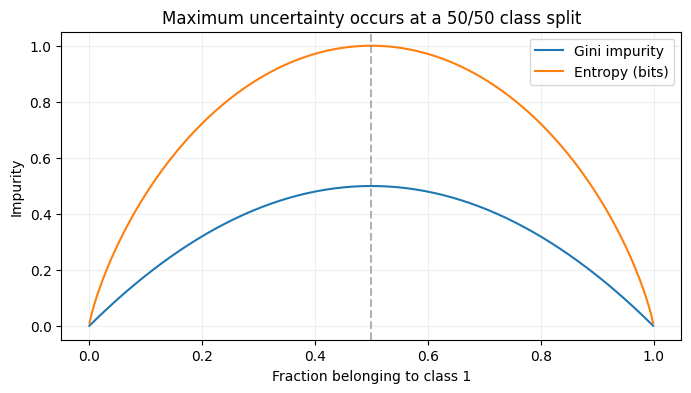

In [24]:
p = np.linspace(0.001, 0.999, 250)
gini_values = 2 * p * (1 - p)
entropy_values = -p * np.log2(p) - (1 - p) * np.log2(1 - p)
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(p, gini_values, label="Gini impurity")
ax.plot(p, entropy_values, label="Entropy (bits)")
ax.axvline(0.5, color="gray", linestyle="--", alpha=0.6)
ax.set(xlabel="Fraction belonging to class 1", ylabel="Impurity", title="Maximum uncertainty occurs at a 50/50 class split")
ax.legend()
ax.grid(alpha=0.2)
plt.show()


## Plot 2 — Information gain across possible thresholds

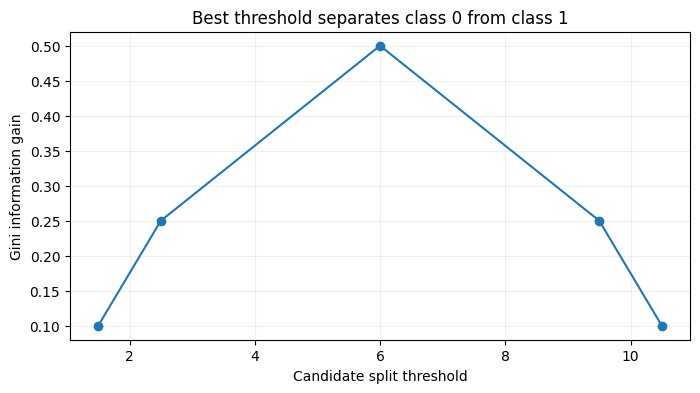

In [25]:
values = np.array([1., 2., 3., 9., 10., 11.])
labels = np.array([0, 0, 0, 1, 1, 1])
thresholds = (values[1:] + values[:-1]) / 2
scores = [information_gain(labels, labels[values >= t], labels[values < t]) for t in thresholds]
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(thresholds, scores, marker="o")
ax.set(xlabel="Candidate split threshold", ylabel="Gini information gain", title="Best threshold separates class 0 from class 1")
ax.grid(alpha=0.2)
plt.show()


## Plot 3 — Draw the custom tree recursively

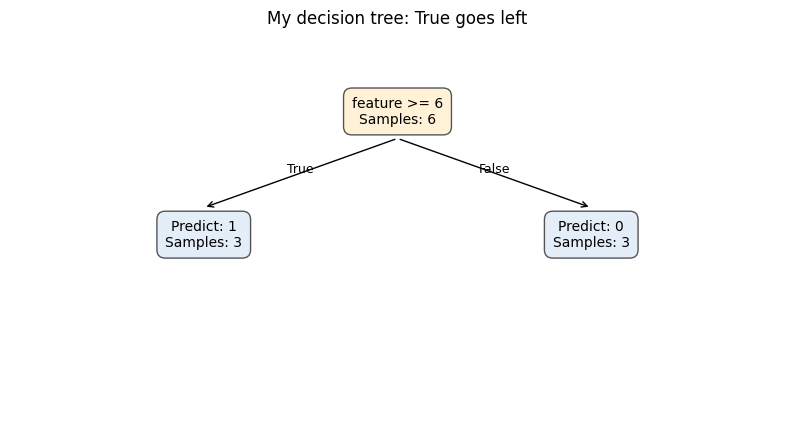

In [26]:
toy_X = pd.DataFrame({"feature": [1, 2, 3, 9, 10, 11]})
toy_y = pd.Series([0, 0, 0, 1, 1, 1])
toy_model = ScratchTree(max_depth=2).fit(toy_X, toy_y)

def annotate_tree(ax, node, x, y, spacing):
    if node.is_leaf:
        text = f"Predict: {node.prediction}\nSamples: {node.samples}"
    else:
        operator = "==" if node.is_categorical else ">="
        text = f"{node.feature} {operator} {node.value:.3g}\nSamples: {node.samples}"
    ax.text(x, y, text, ha="center", va="center", transform=ax.transAxes,
            bbox={"boxstyle": "round,pad=0.6", "fc": "#e4eef9" if node.is_leaf else "#fff2d7", "ec": "#555"})
    if not node.is_leaf:
        for child, child_x, label in [(node.left, x-spacing, "True"), (node.right, x+spacing, "False")]:
            next_y = y - 0.32
            ax.annotate("", xy=(child_x, next_y+0.07), xytext=(x, y-0.07), xycoords="axes fraction", arrowprops={"arrowstyle": "->"})
            ax.text((x+child_x)/2, (y+next_y)/2, label, ha="center", fontsize=9, transform=ax.transAxes)
            annotate_tree(ax, child, child_x, next_y, spacing/2)
fig, ax = plt.subplots(figsize=(10, 5))
ax.set_axis_off()
annotate_tree(ax, toy_model.root, 0.5, 0.83, 0.25)
ax.set_title("My decision tree: True goes left", pad=16)
plt.show()


## Plot 4 — Decision boundaries on a nonlinear dataset

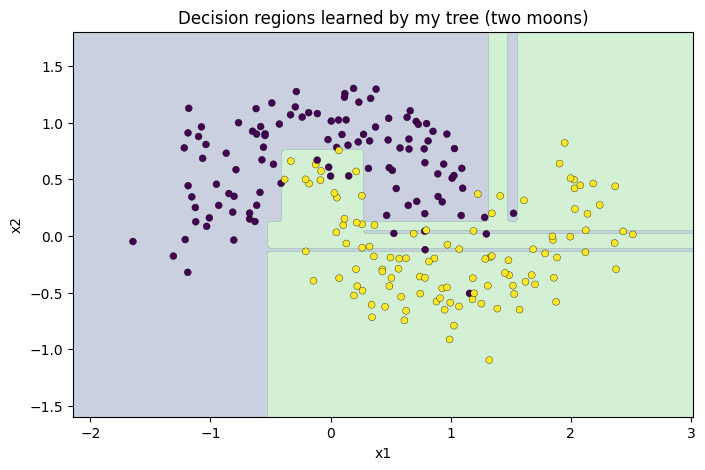

In [27]:
moon_X, moon_y = make_moons(n_samples=220, noise=0.25, random_state=RANDOM_STATE)
moon_df = pd.DataFrame(moon_X, columns=["x1", "x2"])
moon_model = ScratchTree(max_depth=5).fit(moon_df, moon_y)
xx, yy = np.meshgrid(np.linspace(moon_X[:, 0].min()-.5, moon_X[:, 0].max()+.5, 130),
                     np.linspace(moon_X[:, 1].min()-.5, moon_X[:, 1].max()+.5, 130))
grid = pd.DataFrame({"x1": xx.ravel(), "x2": yy.ravel()})
zz = moon_model.predict(grid).reshape(xx.shape)
fig, ax = plt.subplots(figsize=(8, 5))
ax.contourf(xx, yy, zz, alpha=0.27, levels=[-0.5, 0.5, 1.5])
ax.scatter(moon_X[:, 0], moon_X[:, 1], c=moon_y, s=25, edgecolors="k", linewidths=.25)
ax.set(xlabel="x1", ylabel="x2", title="Decision regions learned by my tree (two moons)")
plt.show()


## Plot 5 — Iris: test metrics against scikit-learn

              accuracy  macro F1
model                           
My tree          0.921     0.923
scikit-learn     0.921     0.923


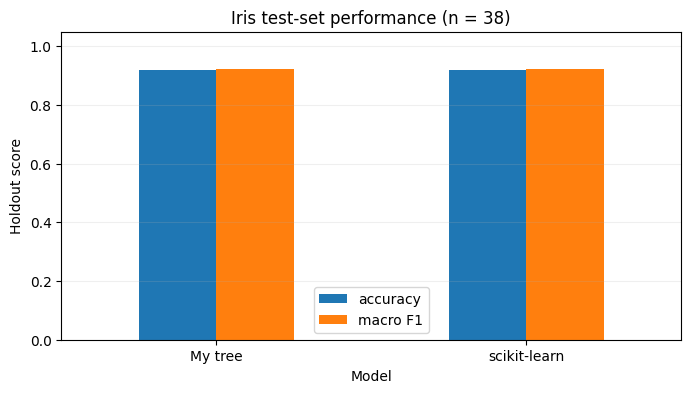

In [28]:
iris = load_iris(as_frame=True)
X_train, X_test, y_train, y_test = train_test_split(iris.data, iris.target, test_size=.25,
                                                  random_state=RANDOM_STATE, stratify=iris.target)
models = {"My tree": ScratchTree(max_depth=4), "scikit-learn": SklearnTree(max_depth=4, random_state=RANDOM_STATE)}
predictions = {}
rows = []
for model_name, estimator in models.items():
    estimator.fit(X_train, y_train)
    pred = estimator.predict(X_test)
    predictions[model_name] = pred
    rows.append({"model": model_name, "accuracy": accuracy_score(y_test, pred),
                 "macro F1": f1_score(y_test, pred, average="macro")})
metric_table = pd.DataFrame(rows).set_index("model")
print(metric_table.round(3))
fig, ax = plt.subplots(figsize=(8, 4))
metric_table.plot.bar(ax=ax, rot=0)
ax.set(xlabel="Model", ylabel="Holdout score", ylim=(0, 1.05), title="Iris test-set performance (n = 38)")
ax.grid(axis="y", alpha=.2)
plt.show()


## Plot 6 — Confusion matrices

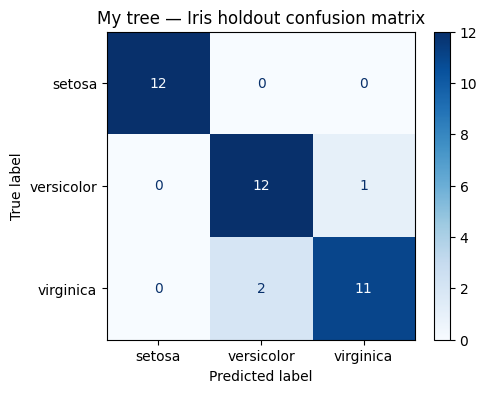

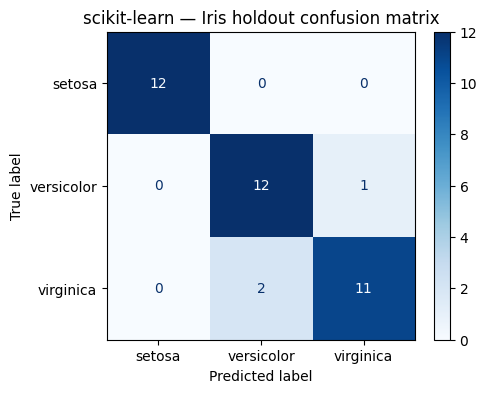

In [29]:
for name, pred in predictions.items():
    fig, ax = plt.subplots(figsize=(5, 4))
    ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=iris.target_names, ax=ax, cmap="Blues")
    ax.set_title(f"{name} — Iris holdout confusion matrix")
    plt.show()


## Plot 7 — Train/test accuracy as maximum depth increases

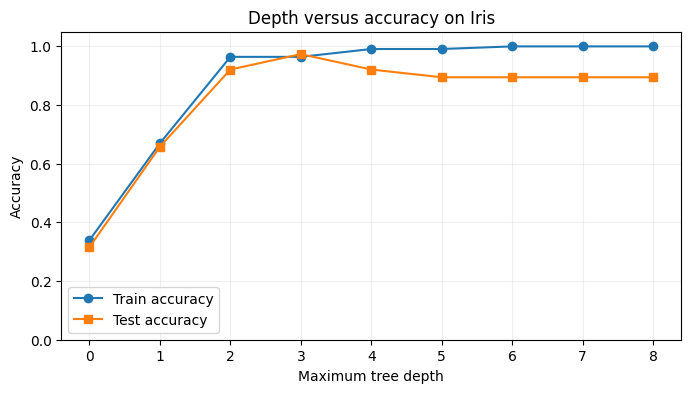

In [30]:
depths = list(range(0, 9))
train_scores, test_scores = [], []
for depth in depths:
    m = ScratchTree(max_depth=depth).fit(X_train, y_train)
    train_scores.append(accuracy_score(y_train, m.predict(X_train)))
    test_scores.append(accuracy_score(y_test, m.predict(X_test)))
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(depths, train_scores, marker="o", label="Train accuracy")
ax.plot(depths, test_scores, marker="s", label="Test accuracy")
ax.set(xlabel="Maximum tree depth", ylabel="Accuracy", ylim=(0, 1.05), title="Depth versus accuracy on Iris")
ax.legend()
ax.grid(alpha=.2)
plt.show()


## Takeaways

- **Gini and entropy** quantify uncertainty and let us rank candidate splits.
- The learned decision regions show why decision trees can capture nonlinear boundaries.
- On Iris, compare the **held-out metrics**, not training accuracy alone.
- A deeper tree often fits training data better but may generalize worse.
- `example.py` provides the extra timing/metric comparisons for **Iris and Titanic**, using the same preprocessing for both implementations.

**Limitations:** This learning implementation does not implement pruning, sample weights, calibrated probabilities, or native missing-value handling. Training time varies across runs/machines; a single timing result is illustrative, not a rigorous benchmark.